# Lesson 00 - Setup check

Before learning anything, make sure the machine is ready:

1. **Python and PyTorch** are installed, and PyTorch can see the **GPU** (graphics card).
   Training a CNN is mostly millions of multiplications; a GPU does them in parallel, typically
   20-50x faster than the CPU.
2. The **data** was copied completely: one big file of spectrograms (`data/mel.npy`, 5.5 GB)
   and one table describing every clip (`data/clips.parquet`).

Run each cell with **Shift+Enter**.

In [8]:
import sys
from pathlib import Path


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("project folder:", ROOT)

project folder: d:\shipsound


## 1. Python, PyTorch and the device

`pick_device()` chooses, in order: an NVIDIA GPU (`cuda`), an Apple GPU (`mps`), or the `cpu`.
The batch size (how many clips the model sees at once) is chosen to fit in the GPU's memory.

In [4]:
import platform
import torch
from device import auto_batch_size, gpu_memory_gb, pick_device

dev = pick_device()
print("Python", platform.python_version(), "| PyTorch", torch.__version__)
print("device:", dev)
if dev.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"| memory {gpu_memory_gb(dev):.1f} GB")
print("batch size for EfficientNet-B0:", auto_batch_size("efficientnet_b0", dev))

Python 3.12.3 | PyTorch 2.11.0+cu128
device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU | memory 4.0 GB
batch size for EfficientNet-B0: 32


## 2. The data

`check_setup.py` opens both files, checks they belong together, and compares checksums
(fingerprints) with the originals made on the preparation laptop. A damaged copy is named so you
know exactly which file to copy again.

In [5]:
import check_setup
status = check_setup.main([])
print("\nexit status:", status, "(0 = ready)")

Python 3.12.3 on Windows 11
PyTorch 2.11.0+cu128 | device: cuda | GPU: NVIDIA GeForce RTX 3050 Laptop GPU, 4.0 GB | default batch size (efficientnet_b0): 32
test calculation on cuda: OK
data: 43208 clips, spectrogram shape (128, 501), folder D:\shipsound\data
data checksums match the original
OK - ready to train

exit status: 0 (0 = ready)


## 3. What one item of data looks like

Each clip is stored as a **log-mel spectrogram**: 128 frequency bands x 501 time steps (10 ms each,
5 seconds in total). Lesson 02 explains exactly how it is made. Here we just peek at one.

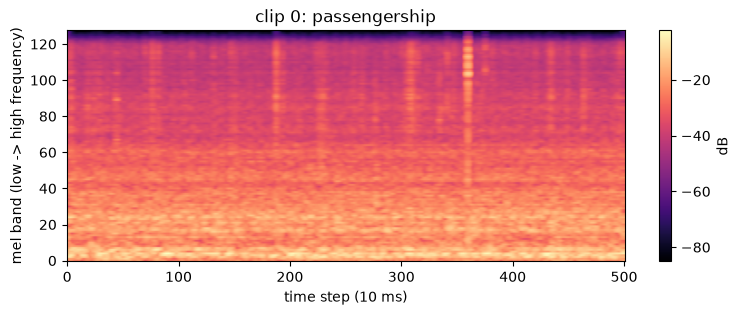

In [6]:
import matplotlib.pyplot as plt
import data as D
from paths import DATA_DIR

mel, table = D.open_features(DATA_DIR)
row = 0
plt.figure(figsize=(9, 3))
plt.imshow(mel[row].astype("float32"), origin="lower", aspect="auto", cmap="magma")
plt.colorbar(label="dB")
plt.title(f"clip {row}: {table.label.iat[row]}")
plt.xlabel("time step (10 ms)"); plt.ylabel("mel band (low -> high frequency)")
plt.show()

## Try it

1. Change `row` to another number (0 to 43207) and look at a few different ship classes.
2. In a terminal (with the environment active) run `python src/benchmark.py` to see how many hours
   each experiment will take on this machine.